# Partie NLP : prétraitement, embeddings et similarité sémantique

Ce notebook documente et justifie toute la chaîne NLP de Moodify : comment on passe d'une phrase libre comme
*« je suis énervée et je veux une musique calme pour réviser »* à un **score de similarité sémantique pour chaque morceau** du catalogue.

Le code réutilisable par l'équipe est dans `src/moodify/` : `preprocessing.py`, `embeddings.py` et `semantic.py`.

## 0. Ce que le sujet exige pour cette partie, et où c'est traité

| Exigence du sujet | Où dans ce notebook |
|---|---|
| « L'analyse doit être **contextuelle et sémantique**, et non purement numérique ou exclusivement fondée sur la correspondance de mots-clés » | §5 (SBERT) et §6 (comparaison avec TF-IDF = mots-clés) |
| « Appliquer des techniques de **prétraitement de texte** » | §2 |
| « **Embeddings de mots** (Word2Vec, GloVe, fastText) » | §4 |
| « **Embeddings contextuels** (BERT, SBERT ou équivalent) » | §5 |
| « Mesures de similarité sémantique (**similarité cosinus**, **clustering sémantique**…) » | §7 (cosinus), §9 (clustering / projection) |
| « Distinguer l'analyse numérique de l'analyse sémantique et contextuelle » | §6 (tests paraphrases, négation, fautes) |
| Thème 4 : « **Extraire les représentations sémantiques** des préférences des utilisateurs » | §7.1 |
| Thème 4 : « **Comparer les descriptions des utilisateurs avec celles des morceaux** » | §7.2-7.3 |
| Thème 4 : « Calculer l'**affinité liée à l'humeur et au genre** musical » | §8 |
| Thème 4 : « **Classer** les morceaux pertinents » | §7.3 |
| « Ces choix doivent être **documentés et justifiés** » | §6 (mesures) et §10 (conclusion) |
| Livrable : « code commenté à chaque étape, documentation dans les notebooks » | Tout le notebook + docstrings des modules |

## 1. Imports et données

In [28]:
import os
os.environ["TQDM_DISABLE"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_VERBOSITY"] = "error"

In [29]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from moodify.preprocessing import clean_text, split_sentences, preprocess_lexical, preprocess_semantic, lemmatize
from moodify.embeddings import get_encoder, cosine_matrix, SBERT_MODELS
from moodify.semantic import SemanticMatcher, build_views

df = pd.read_csv(ROOT / "data" / "moodify_dataset.csv", dtype={"track_id": str}).fillna("")
print(df.shape)
df[["title", "artist", "genre", "mood", "context", "description"]].head()

(684, 29)


,title,artist,genre,mood,context,description
0,I Wanna Be Yours,Arctic Monkeys,Rock,sensuel|joyeux|entraînant,moment à deux|matin|soirée,"Avec « I Wanna Be Yours », Arctic Monkeys prop..."
1,MIDDLE OF THE NIGHT,Elley Duhé,Pop,sensuel|mélancolique|introspectif,nuit|moment à deux|solitude,"Avec « MIDDLE OF THE NIGHT », Elley Duhé propo..."
2,lovely,Billie Eilish,Pop,triste|mélancolique|introspectif,détente|sommeil|pluie|solitude,« lovely » de Billie Eilish est un morceau pop...
3,Call Out My Name,The Weeknd,R&B / Soul / Funk,sensuel|triste,moment à deux|solitude,« Call Out My Name » (The Weeknd) : un titre R...
4,Night Changes,One Direction,Pop,romantique|joyeux|entraînant,matin|moment à deux|soirée,"Signé One Direction, « Night Changes » est un ..."


Le catalogue (`moodify_dataset.csv`, 684 morceaux) fusionne les données réelles Spotify + MuSe + Last.fm et notre jeu « gold » rédigé à la main.

**Ce qui sera comparé aux phrases de l'utilisateur, ce sont des textes**, et non des valeurs audio :
- la `description` en français ;
- les humeurs (`mood`) ;
- les contextes d'écoute (`context`) ;
- les `keywords`.

C'est exactement ce que demande le sujet : *« utiliser des descriptions textuelles pertinentes plutôt que de vous appuyer exclusivement sur des caractéristiques audio numériques »*.

In [30]:
views = build_views(df)
for v in views: print(f"[{v}]", views[v][0][:300], "\n")
print("Longueur moyenne des descriptions :", round(df.description.str.split().map(len).mean(), 1), "mots")

[full] I Wanna Be Yours de Arctic Monkeys. Genre : Rock (indie, rock). Ambiance : sensuel, joyeux, entraînant. À écouter pour : moment à deux, matin, soirée. Avec « I Wanna Be Yours », Arctic Monkeys propose un morceau rock porté par la voix. Le climat est sensuel et joyeux. Il avance sur un tempo lent, av 

[mood] Ambiance sensuel, joyeux, entraînant. Avec « I Wanna Be Yours », Arctic Monkeys propose un morceau rock porté par la voix. Le climat est sensuel et joyeux. Il avance sur un tempo lent, avec une énergie modérée et une production électronique. Parfait pour un moment à deux ou bien commencer la journée 

[context] Idéal pour : moment à deux, matin, soirée. 

Longueur moyenne des descriptions : 46.6 mots


## 2. Prétraitement

On applique **deux pipelines différents**, selon le type de modèle :

| Étape | Pipeline *lexical* (TF-IDF, Word2Vec, fastText) | Pipeline *contextuel* (SBERT) |
|---|---|---|
| Normalisation Unicode, apostrophes, espaces, ponctuation répétée | ✅ | ✅ |
| Découpage en **phrases** (une phrase = une intention) | ✅ | ✅ |
| Minuscules | ✅ | ❌ (le modèle a son propre tokenizer) |
| Tokenisation + élisions (*l'ambiance → ambiance*, mais *aujourd'hui* intact) | ✅ | ❌ |
| Suppression des stopwords | ✅ **sauf les négations** (*pas, sans, jamais…*) | ❌ |
| Lemmatisation (spaCy `fr_core_news_sm`, optionnelle) | ✅ | ❌ |

**Pourquoi un prétraitement minimal pour SBERT ?** Un transformeur encode la phrase *dans son contexte* : les mots-outils, l'ordre des mots et la négation portent du sens.
*« Je ne veux **pas** de musique triste »* perd tout son sens si on enlève « ne » et « pas ». Lemmatiser ou retirer des mots dégraderait donc l'embedding.

In [31]:
exemples = [
    "Aujourd'hui je ne suis pas dans le mood !!! Je suis énervée et je veux une musique calme, sans rap.",
    "J'écoute du lofi pour réviser, ça m'aide à me concentrer.",
    "jsuis trop enervé laisse moi tranquil",
]
for t in exemples:
    print("BRUT        :", t)
    print("Sémantique  :", preprocess_semantic(t))
    print("Lexical     :", preprocess_lexical(t))
    print("Lexical+lem :", preprocess_lexical(t, lemma=True), "(identique si spaCy n'est pas installé)")
    print("Sans garder les négations :", preprocess_lexical(t, keep_negations=False), "\n")

BRUT        : Aujourd'hui je ne suis pas dans le mood !!! Je suis énervée et je veux une musique calme, sans rap.
Sémantique  : ["Aujourd'hui je ne suis pas dans le mood !", 'Je suis énervée et je veux une musique calme, sans rap.']
Lexical     : ["aujourd'hui", 'ne', 'pas', 'mood', 'énervée', 'veux', 'musique', 'calme', 'sans', 'rap']
Lexical+lem : ["aujourd'hui", 'ne', 'pas', 'mood', 'énervée', 'veux', 'musique', 'calme', 'sans', 'rap'] (identique si spaCy n'est pas installé)
Sans garder les négations : ["aujourd'hui", 'mood', 'énervée', 'veux', 'musique', 'calme', 'sans', 'rap'] 

BRUT        : J'écoute du lofi pour réviser, ça m'aide à me concentrer.
Sémantique  : ["J'écoute du lofi pour réviser, ça m'aide à me concentrer."]
Lexical     : ['écoute', 'lofi', 'réviser', 'aide', 'concentrer']
Lexical+lem : ['écoute', 'lofi', 'réviser', 'aide', 'concentrer'] (identique si spaCy n'est pas installé)
Sans garder les négations : ['écoute', 'lofi', 'réviser', 'aide', 'concentrer'] 

BRUT   

Ce qu'on observe :
- **Découpage en phrases** : la première entrée contient deux intentions, un état (« pas dans le mood ») et un souhait (« musique calme »). Les encoder séparément évite de les mélanger.
- **Négations** : si on ne les protège pas, la liste de stopwords supprime « pas » et « sans ». C'est une limite structurelle des approches par mots-clés (voir §6.3).
- **Langage familier** (*jsuis*, *enervé*, *tranquil*) : le pipeline lexical ne le corrige pas. On verra que fastText (n-grammes de caractères) et SBERT (sous-mots) y sont plus robustes.

## 3. Tokenisation

- **Modèles lexicaux** : tokenisation **en mots**. Un mot absent du vocabulaire est perdu (Word2Vec) ou approché par ses n-grammes de caractères (fastText).
- **SBERT** : tokenisation **en sous-mots**, ce qui permet de représenter n'importe quel mot, même mal orthographié, par des morceaux connus.

In [32]:
AVAILABLE = {}          # encodeurs effectivement disponibles sur cette machine
def try_encoder(name):
    try:
        enc = get_encoder(name)
        if enc.name == "tfidf" and name != "tfidf":   # SBERT indisponible -> repli silencieux
            raise RuntimeError("sentence-transformers indisponible")
        return enc
    except Exception as e:
        print(f"⚠ {name} indisponible : {e}")
        return None

sbert = try_encoder("sbert-minilm")
for t in ["énervée", "jsuis enervee", "musique apaisante pour réviser"]:
    print(f"{t!r:35} mots : {preprocess_lexical(t)}")
    if sbert: print(f"{'':35} SBERT : {sbert.tokenize(t)}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3950.09it/s]


'énervée'                           mots : ['énervée']
                                    SBERT : ['▁én', 'er', 'vé', 'e']
'jsuis enervee'                     mots : ['jsuis', 'enervee']
                                    SBERT : ['▁j', 'su', 'is', '▁en', 'er', 've', 'e']
'musique apaisante pour réviser'    mots : ['musique', 'apaisante', 'réviser']
                                    SBERT : ['▁musique', '▁apa', 'is', 'ante', '▁pour', '▁ré', 'viser']


## 4. Embeddings de mots : Word2Vec et fastText

Un embedding de mots associe un vecteur dense à chaque mot. On en déduit l'embedding d'une phrase comme la **moyenne des vecteurs de ses mots**.

- **Word2Vec** (Mikolov et al., 2013) : un vecteur par mot du vocabulaire. Il ne connaît pas les mots absents du vocabulaire.
- **fastText** (Bojanowski et al., 2017) : un mot est la somme de ses **n-grammes de caractères**. Un mot inconnu ou mal orthographié reçoit donc quand même un vecteur.
- **Entraînement** : les deux modèles sont entraînés sur notre corpus, c'est-à-dire les vues textuelles des 684 morceaux et les phrases prototypes des blocs. Un modèle pré-entraîné serait meilleur (par exemple fastText français `cc.fr.300.bin`, environ 7 Go, chargeable avec `get_encoder("fasttext", vectors_path=...)`), mais trop lourd pour le projet.

**Limite de fond** : la moyenne des mots ignore l'ordre et le contexte. Les phrases *« pas calme du tout »* et *« très calme »* obtiennent des vecteurs proches.

In [33]:
corpus = views["full"] + [p for g in ("mood_blocks", "context_blocks")
                          for ps in json.load(open(ROOT/"data/blocks.json", encoding="utf-8"))[g].values() for p in ps]
w2v = get_encoder("word2vec").fit(corpus)
ft = get_encoder("fasttext").fit(corpus)
for mot in ["calme", "énergique", "triste"]:
    print(f"Voisins de « {mot} » — Word2Vec :", [w for w, _ in w2v.kv.most_similar(mot, topn=5)])
    print(f"{'':20}— fastText :", [w for w, _ in ft.kv.most_similar(mot, topn=5)])
print("Mot hors vocabulaire « enervee » dans Word2Vec ?", "enervee" in w2v.kv.key_to_index,
      "| fastText le représente quand même :", ft.kv["enervee"].shape)

Voisins de « calme » — Word2Vec : ['serein', 'cole', 'manuva', 'détente', 'bread']
                    — fastText : ['serein', 'calmes', 'baptism', 'manuva', 'call']
Voisins de « énergique » — Word2Vec : ['view', 'kill', 'duran', 'bounce', 'refrain']
                    — fastText : ['belgique', 'unique', 'view', 'ironique', 'toxique']
Voisins de « triste » — Word2Vec : ['xxxtentacion', 'solitude', 'roads', 'hurts', 'cancer']
                    — fastText : ['tristesse', 'roads', 'emo', 'everybody', 'road']
Mot hors vocabulaire « enervee » dans Word2Vec ? False | fastText le représente quand même : (100,)


## 5. Embeddings contextuels : SBERT

**Sentence-BERT** (Reimers & Gurevych, 2019) est un transformeur BERT affiné pour que **deux phrases de même sens aient des vecteurs proches au sens du cosinus**. C'est exactement l'opération dont nous avons besoin.

Candidats comparés (tous **multilingues**, car nos utilisateurs écrivent en français et parfois en anglais) :

| Modèle | Taille | Dimension | Remarque |
|---|---|---|---|
| `paraphrase-multilingual-MiniLM-L12-v2` | 118 M param. | 384 | rapide sur CPU, entraîné sur des paraphrases |
| `paraphrase-multilingual-mpnet-base-v2` | 278 M param. | 768 | plus précis, plus lourd — **retenu** (voir §10) |
| `intfloat/multilingual-e5-small` | 118 M param. | 384 | modèle récent orienté recherche d'information (préfixe `query:`) |

Au premier lancement, chaque modèle est téléchargé depuis Hugging Face (470 Mo à 1,1 Go), puis mis en cache.

In [34]:
CANDIDATES = ["tfidf", "word2vec", "fasttext", "sbert-minilm", "sbert-mpnet", "e5-small"]
matchers, timing = {}, {}
for name in CANDIDATES:
    t0 = time.time()
    if name in ("tfidf", "word2vec", "fasttext"):
        matchers[name] = SemanticMatcher(name)              # baseline entraînée sur le corpus
    else:
        e = try_encoder(name)
        if e is None: continue
        matchers[name] = SemanticMatcher(e)
    timing[name] = round(time.time() - t0, 1)
    print(f"{name:14} prêt en {timing[name]:5.1f} s | dimension {matchers[name].E['full'].shape[1]}")

tfidf          prêt en   1.3 s | dimension 35586
word2vec       prêt en   8.8 s | dimension 100
fasttext       prêt en   9.4 s | dimension 100


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3354.73it/s]


sbert-minilm   prêt en   2.5 s | dimension 384


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1638.79it/s]


sbert-mpnet    prêt en   3.2 s | dimension 768


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3164.10it/s]


e5-small       prêt en   3.9 s | dimension 384


## 6. Choisir le modèle : comparaison chiffrée

On mesure ce qui compte pour Moodify :
1. **Paraphrases** : deux phrases de même sens **sans mot commun** doivent être plus proches qu'une phrase sans rapport. C'est le cœur de l'analyse sémantique.
2. **Recherche** : pour une requête en langage naturel, les premiers morceaux renvoyés ont-ils la bonne humeur ou le bon contexte ? Mesures : Precision@5, Precision@10, MRR.
3. **Robustesse** : fautes de frappe, langage familier, anglais, négation.
4. **Coût** : temps d'encodage et taille du modèle.

### 6.1 Paraphrases sans mot commun

In [35]:
TRIPLETS = [  # (phrase, paraphrase sans mot commun, phrase sans rapport)
    ("je suis énervée", "j'ai les nerfs, tout m'agace", "je suis de très bonne humeur"),
    ("je suis à bout, j'ai besoin de souffler", "il me faut quelque chose d'apaisant", "mets-moi un son pour faire la fête"),
    ("musique pour réviser", "fond sonore pour bosser mes partiels", "musique pour danser en boîte"),
    ("j'ai le cœur brisé", "ma copine m'a quitté hier", "je viens d'avoir mon diplôme"),
    ("un truc qui donne la pêche", "j'ai besoin d'énergie pour courir", "je veux m'endormir doucement"),
    ("ambiance romantique", "dîner aux chandelles avec mon chéri", "séance de musculation intense"),
    ("I want chill music to study", "musique calme pour travailler", "heavy metal pour se défouler"),
    ("musique triste et mélancolique", "des chansons qui font pleurer", "des chansons joyeuses et ensoleillées"),
]
rows = []
for name, sm in matchers.items():
    enc = sm.encoder
    ok, margins = 0, []
    for a, p, u in TRIPLETS:
        A, P, U = enc.encode([a]), enc.encode([p]), enc.encode([u])
        sp, su = (A @ P.T).item(), (A @ U.T).item()
        ok += sp > su; margins.append(sp - su)
    rows.append({"modèle": name, "paraphrase > sans rapport": f"{ok}/{len(TRIPLETS)}",
                 "marge moyenne": round(float(np.mean(margins)), 3)})
para = pd.DataFrame(rows).set_index("modèle"); para

,paraphrase > sans rapport,marge moyenne
modèle,,
tfidf,1/8,-0.090
word2vec,3/8,0.032
fasttext,5/8,0.018
sbert-minilm,6/8,0.153
sbert-mpnet,7/8,0.199
e5-small,5/8,0.009


**Comment lire le tableau** : la *marge* est la différence entre le cosinus de la paraphrase et celui de la phrase sans rapport. Une marge positive et élevée signifie que le modèle **comprend le sens**, et pas seulement les mots.

TF-IDF ne peut pas réussir les cas sans mot commun : c'est la démonstration concrète que *la correspondance de mots-clés ne suffit pas*.

### 6.2 Recherche dans le catalogue

Pour chaque requête, on connaît l'**humeur** attendue (bloc d'humeur) et parfois le **contexte**. Un morceau renvoyé est considéré pertinent s'il appartient à ces blocs.

Deux évaluations :
- **Tout le catalogue** : les étiquettes viennent des colonnes construites lors de la préparation des données. C'est une étiquette « silver », dont le biais est expliqué plus bas.
- **Jeu gold uniquement** (84 morceaux) : les humeurs et contextes ont été écrits à la main. C'est l'évaluation la plus fiable.

In [36]:
QUERIES = [
    ("Une musique calme et instrumentale pour réviser tard le soir", "Calme & détente", None),
    ("J'ai besoin de me concentrer, quelque chose de doux sans paroles", "Calme & détente", None),
    ("Je suis énervée, je veux me calmer", "Calme & détente", None),
    ("Je suis énervé et j'ai besoin de me défouler", "Colère & défoulement", None),
    ("Des sons rageurs avec des guitares saturées", "Colère & défoulement", None),
    ("Musique motivante pour ma séance de sport", "Énergie & motivation", None),
    ("Un truc qui donne la pêche pour courir", "Énergie & motivation", None),
    ("Des morceaux pour danser en soirée avec des amis", "Fête & danse", None),
    ("Je suis triste, j'ai le cœur brisé", "Mélancolie & introspection", None),
    ("Des chansons mélancoliques pour un jour de pluie", "Mélancolie & introspection", None),
    ("Une ambiance romantique pour un dîner à deux", "Romance & sensualité", None),
    ("Quelque chose de joyeux pour bien commencer la journée", "Joie & bonne humeur", None),
    ("Des sons ensoleillés et optimistes", "Joie & bonne humeur", None),
    ("Une musique planante pour m'évader", "Rêverie & évasion", None),
    ("Des nappes douces pour m'endormir", "Calme & détente", "Sommeil & méditation"),
    ("Musique pour méditer et faire baisser le stress", "Calme & détente", "Sommeil & méditation"),
    ("Un fond sonore pour travailler sans être distrait", None, "Étude & travail"),
    ("I want chill music to study, nothing too loud", "Calme & détente", None),
    ("jsuis trop enervé faut que je me pose", "Calme & détente", None),
    ("Je viens de me faire larguer, je veux pleurer un bon coup", "Mélancolie & introspection", None),
]

def relevant(sub, mood, ctx):
    m = np.ones(len(sub), bool)
    if mood: m &= sub["mood_blocks"].str.contains(mood, regex=False).values
    if ctx:  m &= sub["context_blocks"].str.contains(ctx, regex=False).values
    return m

def evaluate(sm, subset_mask=None):
    p5, p10, rr = [], [], []
    sub = sm.tracks if subset_mask is None else sm.tracks[subset_mask]
    idx = np.arange(len(sm.tracks)) if subset_mask is None else np.where(subset_mask)[0]
    for q, mood, ctx in QUERIES:
        s = sm.semantic_score(q)[idx]
        order = np.argsort(-s)
        rel = relevant(sub, mood, ctx)[order]
        p5.append(rel[:5].mean()); p10.append(rel[:10].mean())
        rr.append(1 / (np.argmax(rel) + 1) if rel.any() else 0)
    return round(np.mean(p5), 3), round(np.mean(p10), 3), round(np.mean(rr), 3)

gold_mask = df["source"].str.contains("gold").values
res = []
for name, sm in matchers.items():
    a = evaluate(sm); g = evaluate(sm, gold_mask)
    res.append({"modèle": name, "P@5 catalogue": a[0], "P@10 catalogue": a[1], "MRR catalogue": a[2],
                "P@5 gold": g[0], "P@10 gold": g[1], "MRR gold": g[2], "temps chargement (s)": timing[name]})
results = pd.DataFrame(res).set_index("modèle"); results

,P@5 catalogue,P@10 catalogue,MRR catalogue,P@5 gold,P@10 gold,MRR gold,temps chargement (s)
modèle,,,,,,,
tfidf,0.69,0.710,0.865,0.69,0.580,0.900,1.3
word2vec,0.56,0.555,0.748,0.65,0.610,0.799,8.8
fasttext,0.65,0.585,0.869,0.69,0.565,0.880,9.4
sbert-minilm,0.58,0.595,0.725,0.59,0.555,0.765,2.5
sbert-mpnet,0.68,0.690,0.854,0.77,0.660,0.917,3.2
e5-small,0.69,0.610,0.871,0.66,0.535,0.942,3.9


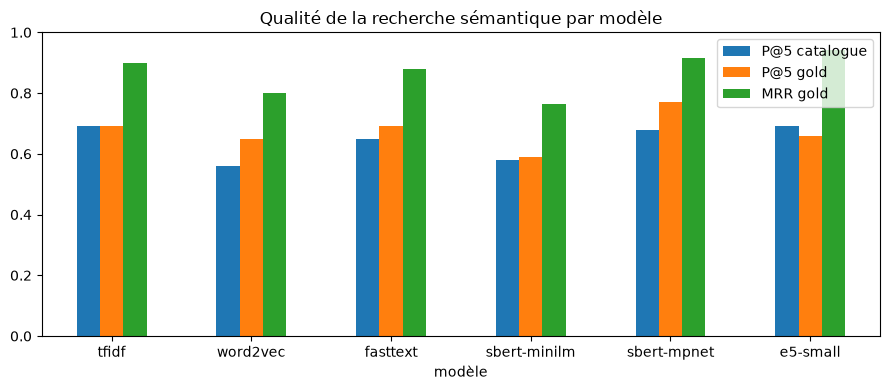

In [37]:
ax = results[["P@5 catalogue", "P@5 gold", "MRR gold"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Qualité de la recherche sémantique par modèle"); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

⚠ **Biais de l'évaluation « catalogue »** : pour les 600 morceaux issus de Spotify / MuSe / Last.fm, les colonnes humeur et contexte et les descriptions viennent des **mêmes** tags. Le score est donc un peu optimiste, surtout pour TF-IDF, qui retrouve les mêmes mots.

L'évaluation **gold**, faite sur les descriptions écrites à la main, est plus juste : c'est elle qui sert de critère principal.

### 6.3 Robustesse : fautes, langage familier, anglais, négation

In [38]:
PAIRS = [  # (A, B, attendu) : True = même sens
    ("je suis énervée", "jsuis enervee", True),
    ("je veux me détendre", "jveux me poser tranquille", True),
    ("musique calme pour étudier", "calm music to study", True),
    ("je veux une musique calme", "je ne veux surtout pas de musique calme", False),
    ("je suis triste", "je ne suis pas triste", False),
]
rows = []
for name, sm in matchers.items():
    r = {"modèle": name}
    for a, b, same in PAIRS:
        r[f"{a[:18]}… ↔ {b[:22]}…"] = round((sm.encoder.encode([a]) @ sm.encoder.encode([b]).T).item(), 2)
    rows.append(r)
pd.DataFrame(rows).set_index("modèle").T

modèle,tfidf,word2vec,fasttext,sbert-minilm,sbert-mpnet,e5-small
je suis énervée… ↔ jsuis enervee…,0.44,0.00,0.71,0.90,0.96,0.90
je veux me détendr… ↔ jveux me poser tranqui…,0.06,0.31,0.63,0.62,0.80,0.90
musique calme pour… ↔ calm music to study…,0.13,0.36,0.61,0.97,0.97,0.95
je veux une musiqu… ↔ je ne veux surtout pas…,0.85,1.00,0.98,0.83,0.72,0.97
je suis triste… ↔ je ne suis pas triste…,0.88,1.00,1.00,0.64,0.36,0.93


**Résultats (exécution du 23/11/2026) et ce qu'il faut en retenir :**
- **Fautes, familier, anglais** : les modèles SBERT gardent un cosinus élevé (mpnet : 0,96 pour « jsuis enervee », 0,97 pour la phrase en anglais). Word2Vec s'effondre sur le mot inconnu (0,00) ; fastText résiste un peu mieux grâce aux n-grammes (0,71).
- **Négation** : c'est le point faible de tous les modèles, à des degrés différents.
  - TF-IDF, Word2Vec, fastText et E5 donnent un cosinus entre 0,85 et 1,00 à des phrases de sens opposé.
  - `mpnet` est le seul à vraiment séparer « je suis triste » de « je ne suis pas triste » (0,36). Mais il rapproche encore « je veux une musique calme » de « je ne veux surtout pas de musique calme » (0,72).

  👉 La négation est donc aussi traitée **par règles** dans le chatbot (« pas de rap » → exclusion du genre). C'est une difficulté rencontrée et sa solution, à présenter.

## 7. Similarité sémantique entre l'utilisateur et chaque morceau

Le modèle retenu est utilisé via `SemanticMatcher`, qui prend le meilleur modèle disponible sur la machine. On reprend l'exemple de texte libre donné dans le sujet pour le Thème 4.

In [39]:
BEST = next((m for m in ["sbert-mpnet", "sbert-minilm", "e5-small", "fasttext"] if m in matchers), "tfidf")
sm = matchers[BEST]; print("Modèle utilisé :", BEST)

user_answers = {   # réponses ouvertes du questionnaire
    "Q01": "Je recherche une musique instrumentale relaxante qui m'aide à me concentrer pendant mes études, "
           "avec une atmosphère calme et apaisante.",                       # exemple du sujet (Thème 4)
    "Q12": "Le dimanche j'aime les ambiances douces, un peu jazzy.",
    "Q13": "Quand je suis énervée j'ai besoin de souffler.",
}

Modèle utilisé : sbert-mpnet


### 7.1 Représentation sémantique des préférences

In [40]:
sents, U = sm.encode_user(user_answers)
print(len(sents), "phrases →", U.shape, "(une ligne = un vecteur normalisé)")
for s in sents: print(" •", s)

3 phrases → (3, 768) (une ligne = un vecteur normalisé)
 • Je recherche une musique instrumentale relaxante qui m'aide à me concentrer pendant mes études, avec une atmosphère calme et apaisante.
 • Le dimanche j'aime les ambiances douces, un peu jazzy.
 • Quand je suis énervée j'ai besoin de souffler.


### 7.2 Similarité cosinus avec **chaque** morceau

$\cos(u, t) = \dfrac{u \cdot t}{\lVert u\rVert\,\lVert t\rVert}$. Les vecteurs sont normalisés, donc un simple produit matriciel donne le score des 684 morceaux en une seule opération.

Comme l'utilisateur écrit **plusieurs phrases**, on agrège :

$$S(t) = \tfrac12\,\text{moyenne}_u \cos(u,t) + \tfrac12\,\max_u \cos(u,t)$$

- la **moyenne** mesure l'accord avec *tout* ce que l'utilisateur a dit ;
- le **max** évite qu'un morceau parfait pour *une* phrase soit noyé par les autres phrases.

On calcule ce score sur **trois vues** de chaque morceau (globale, humeur, contexte), puis on les combine avec les poids 0,5 / 0,3 / 0,2. La vue globale porte le sens général ; l'humeur est la promesse du produit ; le contexte sert à affiner.

In [41]:
sents, S = sm.similarity_matrix(user_answers, view="full")
print("Matrice phrases × morceaux :", S.shape)
top = sm.rank(user_answers, k=10)
top[["title", "artist", "genre", "cos_full", "cos_mood", "cos_context", "semantic_score", "best_user_sentence"]]

Matrice phrases × morceaux : (3, 684)


,title,artist,genre,cos_full,cos_mood,cos_context,semantic_score,best_user_sentence
0,Gymnopédie No. 1,Erik Satie,Classique,0.550782,0.610818,0.540879,0.566812,Je recherche une musique instrumentale relaxan...
1,Peace Piece,Bill Evans,Jazz / Blues,0.543396,0.540589,0.536288,0.541132,Je recherche une musique instrumentale relaxan...
2,Don't Know Why,Norah Jones,Jazz / Blues,0.468370,0.614477,0.600117,0.538552,"Le dimanche j'aime les ambiances douces, un pe..."
3,Threnody,Goldmund,Ambient,0.549759,0.496627,0.553943,0.534656,Je recherche une musique instrumentale relaxan...
4,An Ending (Ascent),Brian Eno,Ambient,0.473188,0.610832,0.551741,0.530192,Je recherche une musique instrumentale relaxan...
5,i'm closing my eyes,potsu,Lo-fi / Chill,0.501930,0.554051,0.552164,0.527613,Je recherche une musique instrumentale relaxan...
6,Alone in Kyoto,Air,Ambient,0.487158,0.551372,0.573219,0.523635,Je recherche une musique instrumentale relaxan...
7,Ambre,Nils Frahm,Ambient,0.516378,0.505939,0.553943,0.520759,Je recherche une musique instrumentale relaxan...
8,Aruarian Dance,Nujabes,Lo-fi / Chill,0.435777,0.624282,0.570575,0.519288,Je recherche une musique instrumentale relaxan...
9,Our House,"Crosby, Stills, Nash & Young",Jazz / Blues,0.493701,0.560199,0.519174,0.518745,"Le dimanche j'aime les ambiances douces, un pe..."


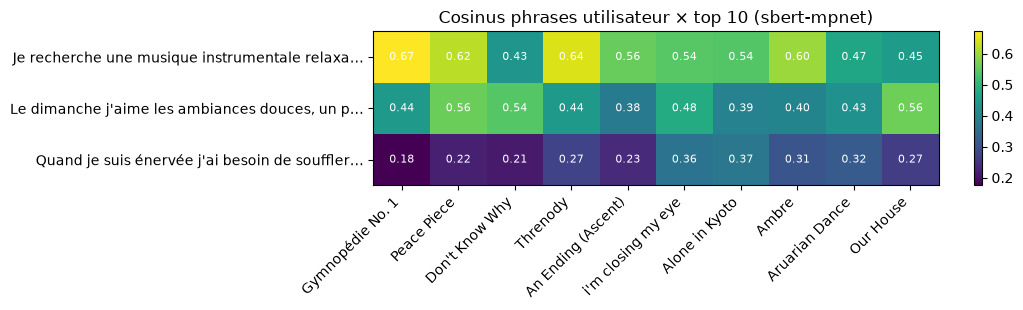

In [42]:
idx = [df.index[df.track_id == t][0] for t in top.track_id]
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(S[:, idx], cmap="viridis", aspect="auto")
ax.set_xticks(range(len(idx)), [f"{df.title[i][:18]}" for i in idx], rotation=45, ha="right")
ax.set_yticks(range(len(sents)), [s[:45] + "…" for s in sents])
for i in range(S.shape[0]):
    for j, k in enumerate(idx): ax.text(j, i, f"{S[i, k]:.2f}", ha="center", va="center", color="w", fontsize=8)
fig.colorbar(im); ax.set_title(f"Cosinus phrases utilisateur × top 10 ({BEST})"); plt.tight_layout(); plt.show()

### 7.3 Distribution des scores et calibration

Les cosinus bruts n'ont pas la même échelle selon les modèles. Avec SBERT, deux textes sans rapport ont typiquement un cosinus entre 0,1 et 0,3 ; un très bon match se situe entre 0,6 et 0,8. La distribution ci-dessous sert à fixer les bornes de calibration utilisées pour l'affichage en pourcentage (`COS_LOW` / `COS_HIGH` dans `config.py`) : on prend environ le 5e et le 99,5e centile.

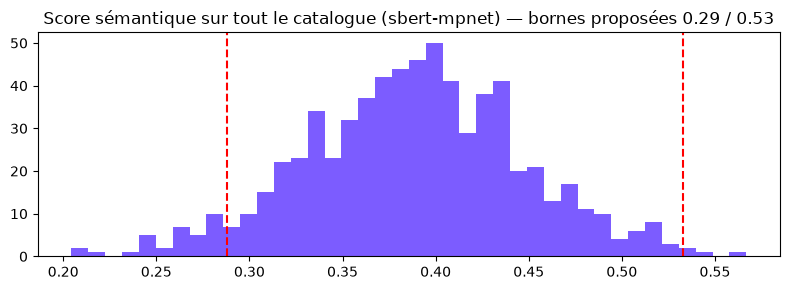

Calibration proposée : COS_LOW=0.29, COS_HIGH=0.53 -> score affiché = (s - LOW) / (HIGH - LOW)


In [43]:
s_all = sm.semantic_score(user_answers)
lo, hi = np.percentile(s_all, [5, 99.5])
plt.figure(figsize=(8, 3)); plt.hist(s_all, bins=40, color="#7C5CFF")
for x in (lo, hi): plt.axvline(x, color="red", ls="--")
plt.title(f"Score sémantique sur tout le catalogue ({BEST}) — bornes proposées {lo:.2f} / {hi:.2f}")
plt.tight_layout(); plt.show()
print(f"Calibration proposée : COS_LOW={lo:.2f}, COS_HIGH={hi:.2f} -> score affiché = (s - LOW) / (HIGH - LOW)")

## 8. Affinité liée à l'humeur et au genre

- **Humeur** : on compare les phrases de l'utilisateur aux phrases prototypes de chaque bloc d'humeur (`data/blocks.json`), comme dans l'exemple « blocs de compétences » du sujet.

  $S_{bloc} = \tfrac12\,\text{moyenne}_u \max_p \cos(u,p) + \tfrac12 \max_u \max_p \cos(u,p)$

  Ces affinités alimentent le **score de couverture** $\sum W_i S_i / \sum W_i$ (partie Recommandation).
- **Genre** : cosinus entre l'utilisateur et le **centroïde sémantique** des morceaux de chaque genre. L'utilisateur peut ainsi découvrir un genre qu'il n'a pas coché, mais que ses mots décrivent.

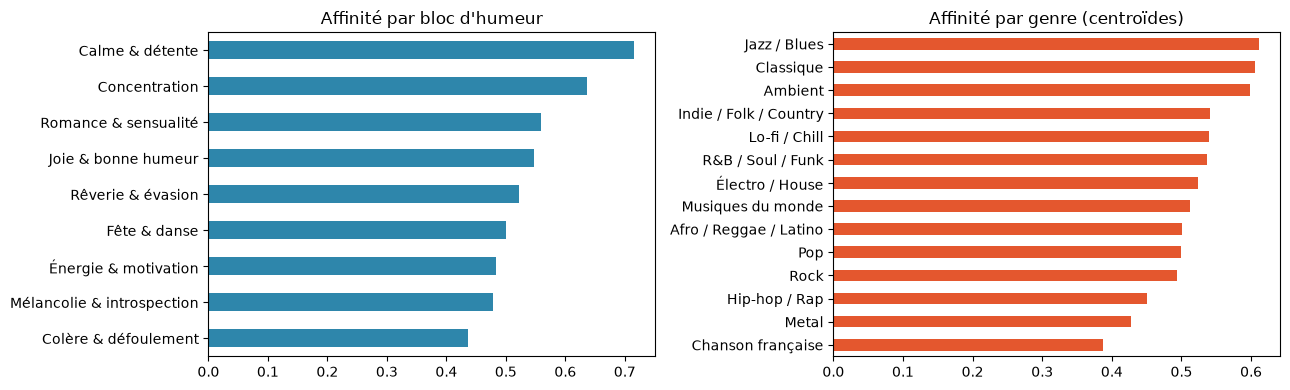

Mots-clés expliquant le n°1 : [('classical', 0.423), ('nostalgique', 0.406), ('instrumental', 0.405)]


In [44]:
mood_aff, genre_aff = sm.mood_affinity(user_answers), sm.genre_affinity(user_answers)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.Series(mood_aff).sort_values().plot.barh(ax=axes[0], color="#2E86AB", title="Affinité par bloc d'humeur")
pd.Series(genre_aff).sort_values().plot.barh(ax=axes[1], color="#E4572E", title="Affinité par genre (centroïdes)")
plt.tight_layout(); plt.show()
print("Mots-clés expliquant le n°1 :", sm.matched_keywords(top.track_id[0], user_answers))

## 9. Clustering sémantique du catalogue

Le sujet cite le *clustering sémantique* comme mesure possible. On projette les embeddings des morceaux en 2D (t-SNE) et on les regroupe avec KMeans.

Si des groupes cohérents apparaissent (par humeur et par genre), les embeddings capturent bien l'**ambiance**. Ces groupes servent aussi aux **communautés** de l'application.

Silhouette (cosinus) : 0.111


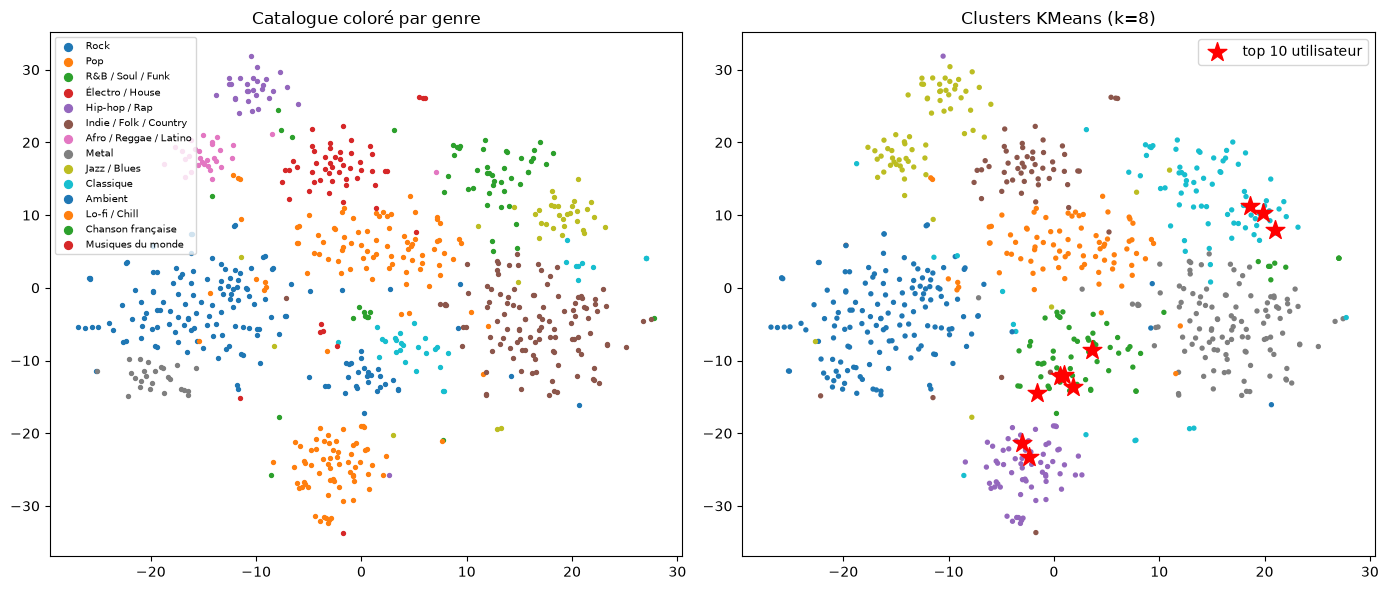

Cluster 0 (146) : humeurs ['joyeux', 'entraînant', 'mélancolique'] | genres ['Rock', 'Metal']
Cluster 1 (81) : humeurs ['joyeux', 'entraînant', 'mélancolique'] | genres ['Pop', 'Rock']
Cluster 2 (68) : humeurs ['mélancolique', 'introspectif', 'doux'] | genres ['Classique', 'Ambient']
Cluster 3 (67) : humeurs ['calme', 'serein', 'dansant'] | genres ['Lo-fi / Chill', 'Hip-hop / Rap']
Cluster 4 (55) : humeurs ['joyeux', 'entraînant', 'dansant'] | genres ['Électro / House', 'Rock']
Cluster 5 (113) : humeurs ['doux', 'mélancolique', 'serein'] | genres ['Indie / Folk / Country', 'Rock']
Cluster 6 (66) : humeurs ['joyeux', 'entraînant', 'dansant'] | genres ['Afro / Reggae / Latino', 'Hip-hop / Rap']
Cluster 7 (88) : humeurs ['serein', 'calme', 'romantique'] | genres ['R&B / Soul / Funk', 'Jazz / Blues']


In [45]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
E = sm.E["full"]
X2 = TSNE(n_components=2, metric="cosine", random_state=0, perplexity=30).fit_transform(E)
km = KMeans(n_clusters=8, n_init=10, random_state=0).fit(E)
print("Silhouette (cosinus) :", round(silhouette_score(E, km.labels_, metric="cosine"), 3))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for g in df.genre.unique():
    m = (df.genre == g).values; axes[0].scatter(X2[m, 0], X2[m, 1], s=8, label=g)
axes[0].legend(fontsize=7, markerscale=2); axes[0].set_title("Catalogue coloré par genre")
axes[1].scatter(X2[:, 0], X2[:, 1], c=km.labels_, s=8, cmap="tab10"); axes[1].set_title("Clusters KMeans (k=8)")
u2 = X2[np.argsort(-sm.semantic_score(user_answers))[:10]]
axes[1].scatter(u2[:, 0], u2[:, 1], marker="*", s=200, c="red", label="top 10 utilisateur"); axes[1].legend()
plt.tight_layout(); plt.show()
for c in range(8):
    sub = df[km.labels_ == c]
    print(f"Cluster {c} ({len(sub)}) : humeurs {sub['mood'].str.split('|').explode().value_counts().index[:3].tolist()} | genres {sub.genre.value_counts().index[:2].tolist()}")

## 10. Conclusion : choix et justification

**Modèle retenu : SBERT multilingue `paraphrase-multilingual-mpnet-base-v2`.**

| Critère | TF-IDF | Word2Vec | fastText | SBERT MiniLM | **SBERT mpnet** | E5-small |
|---|---|---|---|---|---|---|
| Paraphrases réussies (§6.1) | 1/8 | 3/8 | 5/8 | 6/8 | **7/8** | 5/8 |
| Marge moyenne (§6.1) | −0,090 | 0,032 | 0,018 | 0,153 | **0,199** | 0,009 |
| P@5 jeu gold (§6.2) | 0,69 | 0,65 | 0,69 | 0,59 | **0,77** | 0,66 |
| P@10 jeu gold (§6.2) | 0,58 | 0,61 | 0,57 | 0,56 | **0,66** | 0,54 |
| MRR jeu gold (§6.2) | 0,90 | 0,80 | 0,88 | 0,77 | 0,92 | **0,94** |
| « triste » ↔ « pas triste » (§6.3, plus bas = mieux) | 0,88 | 1,00 | 1,00 | 0,64 | **0,36** | 0,93 |
| Dimension | 35 586 | 100 | 100 | 384 | 768 | 384 |

Justification :
1. **C'est le modèle qui comprend le mieux le sens.** Il réussit 7 paraphrases sans mot commun sur 8, avec la plus grande marge. TF-IDF n'en réussit qu'une : la correspondance de mots-clés ne suffit pas, comme le dit le sujet.
2. **C'est le meilleur en recherche sur le jeu gold**, celui dont les étiquettes sont écrites à la main : P@5 = 0,77 et P@10 = 0,66. E5 a un MRR un peu plus élevé (0,94 contre 0,92), donc son premier résultat est souvent bon, mais la suite de son classement est plus faible.
3. **C'est le plus robuste** : fautes, langage familier, anglais, et c'est le seul modèle qui distingue en partie la négation (0,36).
4. **Son coût reste raisonnable.** Il est plus lourd que MiniLM (768 dimensions, 278 M paramètres), mais il se charge en quelques secondes. Les embeddings des 684 morceaux sont calculés une fois puis mis en cache. À chaque requête, seule la phrase de l'utilisateur est encodée.

**Pourquoi pas MiniLM, prévu au départ ?** Il est plus léger, mais nettement moins bon sur notre jeu gold (P@5 = 0,59). Le gain de vitesse ne compense pas la perte de qualité pour un catalogue de cette taille.

**Remarques honnêtes sur l'évaluation :**
- 20 requêtes et 84 morceaux gold : un écart de 0,05 à 0,1 correspond à quelques morceaux. Les tendances sont nettes, mais l'évaluation reste à petite échelle.
- TF-IDF est artificiellement bon sur l'évaluation « catalogue », car les descriptions et les étiquettes réutilisent les mêmes mots. C'est pourquoi le test des paraphrases et le jeu gold servent de critères principaux.
- Le clustering (§9) regroupe surtout par **genre** (silhouette 0,10) : les descriptions mentionnent toutes leur genre. Pour les communautés par ambiance, une piste est de regrouper sur la vue humeur (`sm.E["mood"]`).

**Rôle des autres modèles** : TF-IDF, Word2Vec et fastText sont conservés comme **bases de comparaison**, comme le demande le sujet. TF-IDF sert aussi de repli automatique si SBERT ne peut pas être chargé.

**Limite connue et solution** : même mpnet rapproche « je veux du calme » et « je ne veux pas de calme » (0,72). La négation est donc aussi gérée par des règles dans le chatbot.

**Interface pour l'équipe :**
```python
from moodify.semantic import SemanticMatcher
sm = SemanticMatcher()                          # mpnet par défaut, chargé une fois au démarrage de l'API
sm.rank(reponses_libres, k=10)                  # morceaux classés + cosinus par vue
sm.semantic_score(reponses_libres)              # 1 score par morceau (pour la formule de Messade)
sm.mood_affinity(reponses_libres)               # blocs d'humeur (score de couverture, profil de Maureen)
sm.genre_affinity(reponses_libres)              # affinité par genre
sm.matched_keywords(track_id, reponses_libres)  # mots-clés pour l'explication
```